In [19]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from xgboost import XGBClassifier

file = r"D:\Downloads\archive (1)\2012-2013-data-with-predictions-4-final.csv"

# 100,000 rows
df = pd.read_csv(file, nrows=100000)

print("Dataset loaded")
print("Shape:", df.shape)


# Correct ko numeric banao
df["correct"] = pd.to_numeric(df["correct"], errors="coerce")

# Sirf binary labels 0 aur 1 rakho
df = df[df["correct"].isin([0, 1])].copy()

print("After cleaning:", df.shape)
print("\nTarget distribution:")
print(df["correct"].value_counts())

# Numeric features
numeric_cols = df.select_dtypes(include=["number"]).columns.tolist()

# Target ko remove karo
features = [c for c in numeric_cols if c != "correct"]

X = df[features].fillna(0)
y = df["correct"].astype(int)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))

# XGBoost
model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss"
)

# Train
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_prob)

print("\n========== MODEL RESULTS ==========")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("AUC      :", round(auc, 4))

Dataset loaded
Shape: (100000, 35)
After cleaning: (99926, 35)

Target distribution:
correct
1.0    67894
0.0    32032
Name: count, dtype: int64

Training rows: 79940
Testing rows: 19986

========== MODEL RESULTS ==========
Accuracy : 0.9289
Precision: 0.9075
Recall   : 0.9968
F1 Score : 0.9501
AUC      : 0.9671



SHAP - RANDOM FOREST
Random Forest SHAP shape: (1000, 7, 2)

Random Forest SHAP Importance:


,Feature,Mean_ABS_SHAP
0,attempt_count,0.205868
1,hint_count,0.096626
4,bottom_hint,0.044901
6,overlap_time,0.025393
3,skill_id,0.018100
2,ms_first_response,0.010025
5,actions,0.000000



Random Forest SHAP Plot:


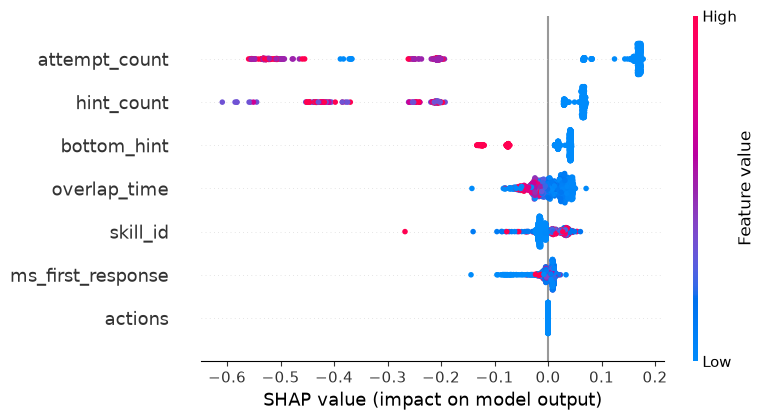


SHAP - XGBOOST
XGBoost SHAP shape: (1000, 7)

XGBoost SHAP Importance:


,Feature,Mean_ABS_SHAP
0,attempt_count,1.910899
1,hint_count,0.975143
4,bottom_hint,0.216409
3,skill_id,0.193956
6,overlap_time,0.164519
2,ms_first_response,0.106485
5,actions,0.000000



XGBoost SHAP Plot:


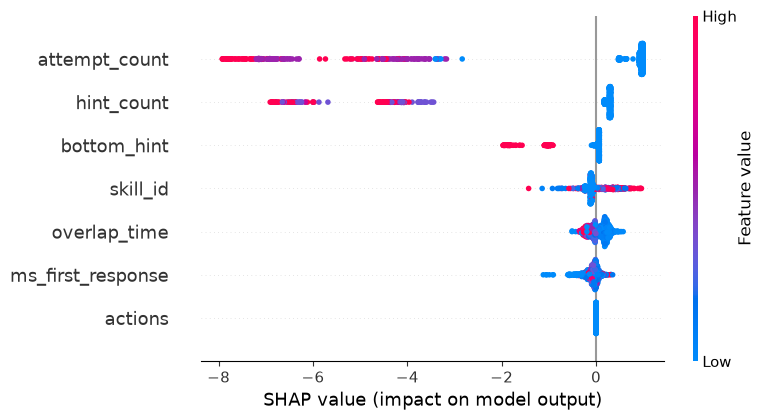


CREATING LEARNING PROFILE

SKILL-WISE LEARNING PROFILE


,skill_id,questions,accuracy,avg_attempts,avg_hints,avg_response_time,mastery_level
0,0.0,55781,66.420466,1.323712,0.282103,44017.929976,Developing
1,1.0,151,59.602649,1.847682,0.331126,37684.947020,Needs Improvement
2,2.0,12,83.333333,1.000000,0.000000,27827.416667,Strong
3,3.0,2,50.000000,1.000000,0.000000,16822.000000,Needs Improvement
4,4.0,190,75.263158,1.363158,0.421053,49885.010526,Developing
5,5.0,107,65.420561,1.177570,0.140187,32219.588785,Developing
6,6.0,34,58.823529,1.441176,0.029412,33398.647059,Needs Improvement
7,7.0,11,45.454545,1.272727,0.000000,6038.545455,Needs Improvement
8,8.0,130,72.307692,1.446154,0.184615,34055.500000,Developing
9,9.0,18,50.000000,1.444444,0.166667,104477.166667,Needs Improvement



WEAK SKILLS


,skill_id,questions,accuracy,avg_attempts,avg_hints,avg_response_time,mastery_level
21,23.0,1,0.000000,2.000000,0.000000,301732.000000,Needs Improvement
106,218.0,1,0.000000,2.000000,2.000000,37295.000000,Needs Improvement
108,223.0,4,0.000000,1.750000,0.000000,60020.750000,Needs Improvement
78,100.0,2,0.000000,5.500000,1.500000,167254.500000,Needs Improvement
101,212.0,1,0.000000,1.000000,0.000000,15684.000000,Needs Improvement
197,387.0,3,0.000000,4.333333,0.666667,108861.666667,Needs Improvement
150,313.0,1,0.000000,2.000000,1.000000,31432.000000,Needs Improvement
174,345.0,1,0.000000,4.000000,0.000000,3769.000000,Needs Improvement
240,606.0,2,0.000000,1.000000,0.000000,83864.500000,Needs Improvement
233,597.0,2,0.000000,1.000000,0.000000,133887.000000,Needs Improvement



PERSONALIZED RECOMMENDATIONS


,attempt_count,hint_count,ms_first_response,skill_id,correct_probability,risk_probability,risk_level,main_risk_factor,recommendation
52141,1,0,14735,0.0,0.897674,0.102326,LOW,skill_id,Focus on additional practice for this skill.
74197,1,0,4110,0.0,0.871705,0.128295,LOW,ms_first_response,Continue practice while gradually improving re...
44480,1,0,29018,39.0,0.798786,0.201214,LOW,skill_id,Focus on additional practice for this skill.
3051,1,0,26479,0.0,0.896253,0.103747,LOW,skill_id,Focus on additional practice for this skill.
38687,1,0,367169,0.0,0.841934,0.158066,LOW,ms_first_response,Review the concept and use short timed practic...
27889,13,0,31965,0.0,0.000606,0.999394,HIGH,attempt_count,Revise the related concept and practice simila...
39528,1,0,5128,365.0,0.839042,0.160958,LOW,ms_first_response,Continue practice while gradually improving re...
43653,1,0,16778,336.0,0.946063,0.053937,LOW,ms_first_response,Continue practice while gradually improving re...
11817,1,0,11485,47.0,0.944064,0.055936,LOW,ms_first_response,Continue practice while gradually improving re...
59287,3,0,1046,0.0,0.003853,0.996147,HIGH,attempt_count,Practice more questions from the related skill.



SAVING MODELS AND RESULTS

COMPLETE
Random Forest      : READY
XGBoost            : READY
RF SHAP            : READY
XGBoost SHAP       : READY
Risk Prediction    : READY
Skill Profile      : READY
Recommendations    : READY

Saved in:
C:\Users\Hp\Downloads


In [2]:
# ============================================================
# SHAP - RANDOM FOREST + XGBOOST + RECOMMENDATIONS
# ============================================================

print("\n==============================================")
print("SHAP - RANDOM FOREST")
print("==============================================")

X_shap = X_test.iloc[:1000].copy()

# ------------------------------------------------------------
# RANDOM FOREST SHAP
# ------------------------------------------------------------

rf_explainer = shap.TreeExplainer(
    rf_model
)

rf_shap_values = rf_explainer.shap_values(
    X_shap
)

print(
    "Random Forest SHAP shape:",
    np.array(rf_shap_values).shape
)

rf_shap_array = np.array(
    rf_shap_values
)

# SHAP can return:
# (samples, features, classes)
# or
# (classes, samples, features)
# or
# (samples, features)

if rf_shap_array.ndim == 3:

    if rf_shap_array.shape[-1] == 2:

        rf_shap_class1 = rf_shap_array[:, :, 1]

    elif rf_shap_array.shape[0] == 2:

        rf_shap_class1 = rf_shap_array[1]

    else:

        rf_shap_class1 = rf_shap_array[:, :, 0]

else:

    rf_shap_class1 = rf_shap_array


rf_shap_importance = pd.DataFrame({

    "Feature": features,

    "Mean_ABS_SHAP": np.abs(
        rf_shap_class1
    ).mean(axis=0)

}).sort_values(
    "Mean_ABS_SHAP",
    ascending=False
)


print("\nRandom Forest SHAP Importance:")

display(
    rf_shap_importance
)


# ============================================================
# RANDOM FOREST SHAP PLOT
# ============================================================

print("\nRandom Forest SHAP Plot:")

shap.summary_plot(
    rf_shap_class1,
    X_shap
)


# ============================================================
# SHAP - XGBOOST
# ============================================================

print("\n==============================================")
print("SHAP - XGBOOST")
print("==============================================")

xgb_explainer = shap.TreeExplainer(
    xgb_model
)

xgb_shap_values = xgb_explainer.shap_values(
    X_shap
)

xgb_shap_array = np.array(
    xgb_shap_values
)

print(
    "XGBoost SHAP shape:",
    xgb_shap_array.shape
)


if xgb_shap_array.ndim == 3:

    if xgb_shap_array.shape[-1] == 2:

        xgb_shap_class1 = xgb_shap_array[:, :, 1]

    elif xgb_shap_array.shape[0] == 2:

        xgb_shap_class1 = xgb_shap_array[1]

    else:

        xgb_shap_class1 = xgb_shap_array[:, :, 0]

else:

    xgb_shap_class1 = xgb_shap_array


xgb_shap_importance = pd.DataFrame({

    "Feature": features,

    "Mean_ABS_SHAP": np.abs(
        xgb_shap_class1
    ).mean(axis=0)

}).sort_values(
    "Mean_ABS_SHAP",
    ascending=False
)


print("\nXGBoost SHAP Importance:")

display(
    xgb_shap_importance
)


# ============================================================
# XGBOOST SHAP PLOT
# ============================================================

print("\nXGBoost SHAP Plot:")

shap.summary_plot(
    xgb_shap_class1,
    X_shap
)


# ============================================================
# COMPLETE XGBOOST SHAP FOR TEST DATA
# ============================================================

print("\n==============================================")
print("CREATING LEARNING PROFILE")
print("==============================================")

xgb_test_shap_values = xgb_explainer.shap_values(
    X_test
)

xgb_test_array = np.array(
    xgb_test_shap_values
)

if xgb_test_array.ndim == 3:

    if xgb_test_array.shape[-1] == 2:

        xgb_test_class1 = (
            xgb_test_array[:, :, 1]
        )

    elif xgb_test_array.shape[0] == 2:

        xgb_test_class1 = (
            xgb_test_array[1]
        )

    else:

        xgb_test_class1 = (
            xgb_test_array[:, :, 0]
        )

else:

    xgb_test_class1 = xgb_test_array


# ============================================================
# LEARNING PROFILE
# ============================================================

profile = X_test.copy()

profile["actual"] = y_test.values

profile["predicted"] = xgb_pred

profile["correct_probability"] = xgb_prob

profile["risk_probability"] = (
    1 - xgb_prob
)


# ============================================================
# RISK LEVEL
# ============================================================

def get_risk(prob):

    if prob >= 0.60:
        return "HIGH"

    elif prob >= 0.30:
        return "MEDIUM"

    else:
        return "LOW"


profile["risk_level"] = (
    profile["risk_probability"]
    .apply(get_risk)
)


# ============================================================
# ADD SHAP VALUES
# ============================================================

for i, feature in enumerate(features):

    profile[
        "SHAP_" + feature
    ] = xgb_test_class1[:, i]


# ============================================================
# MAIN RISK FACTOR
# ============================================================

def get_main_factor(row):

    values = {}

    for feature in features:

        values[feature] = row[
            "SHAP_" + feature
        ]

    negative = {
        k: v
        for k, v in values.items()
        if v < 0
    }

    if len(negative) == 0:

        return "No strong negative factor"

    return min(
        negative,
        key=negative.get
    )


profile["main_risk_factor"] = (
    profile.apply(
        get_main_factor,
        axis=1
    )
)


# ============================================================
# RECOMMENDATION ENGINE
# ============================================================

def make_recommendation(row):

    factor = row["main_risk_factor"]

    attempts = row["attempt_count"]

    hints = row["hint_count"]

    response = row["ms_first_response"]

    risk = row["risk_level"]


    if factor == "attempt_count":

        if attempts >= 5:

            return (
                "Revise the related concept "
                "and practice similar questions."
            )

        return (
            "Practice more questions "
            "from the related skill."
        )


    if factor == "hint_count":

        if hints >= 3:

            return (
                "Review the concept explanation "
                "and practice with fewer hints."
            )

        return (
            "Review the concept and solve "
            "additional practice questions."
        )


    if factor == "bottom_hint":

        return (
            "Review the concept explanation "
            "before attempting similar questions."
        )


    if factor == "ms_first_response":

        if response > 30000:

            return (
                "Review the concept and use "
                "short timed practice sessions."
            )

        return (
            "Continue practice while gradually "
            "improving response speed."
        )


    if factor == "overlap_time":

        return (
            "Review the concept and practice "
            "questions with focused attention."
        )


    if factor == "skill_id":

        return (
            "Focus on additional practice "
            "for this skill."
        )


    if risk == "HIGH":

        return (
            "Prioritize concept revision "
            "and targeted practice."
        )


    if risk == "MEDIUM":

        return (
            "Review recent mistakes and "
            "continue targeted practice."
        )


    return (
        "Continue regular practice and "
        "progressively attempt harder questions."
    )


profile["recommendation"] = (
    profile.apply(
        make_recommendation,
        axis=1
    )
)


# ============================================================
# SKILL-WISE LEARNING PROFILE
# ============================================================

print("\n==============================================")
print("SKILL-WISE LEARNING PROFILE")
print("==============================================")

skill_profile = (

    assist
    .groupby("skill_id")
    .agg(

        questions=("correct", "count"),

        accuracy=("correct", "mean"),

        avg_attempts=(
            "attempt_count",
            "mean"
        ),

        avg_hints=(
            "hint_count",
            "mean"
        ),

        avg_response_time=(
            "ms_first_response",
            "mean"
        )

    )
    .reset_index()
)


skill_profile["accuracy"] = (
    skill_profile["accuracy"] * 100
)


skill_profile["mastery_level"] = np.select(

    [
        skill_profile["accuracy"] >= 80,

        skill_profile["accuracy"] >= 60
    ],

    [
        "Strong",

        "Developing"
    ],

    default="Needs Improvement"
)


display(
    skill_profile.head(20)
)


# ============================================================
# WEAK SKILLS
# ============================================================

print("\n==============================================")
print("WEAK SKILLS")
print("==============================================")

weak_skills = (
    skill_profile[
        skill_profile["accuracy"] < 60
    ]
    .sort_values(
        "accuracy"
    )
)

display(
    weak_skills.head(20)
)


# ============================================================
# RECOMMENDATIONS
# ============================================================

print("\n==============================================")
print("PERSONALIZED RECOMMENDATIONS")
print("==============================================")

recommendations = profile[
    [
        "attempt_count",
        "hint_count",
        "ms_first_response",
        "skill_id",
        "correct_probability",
        "risk_probability",
        "risk_level",
        "main_risk_factor",
        "recommendation"
    ]
]

display(
    recommendations.head(20)
)


# ============================================================
# SAVE EVERYTHING
# ============================================================

print("\n==============================================")
print("SAVING MODELS AND RESULTS")
print("==============================================")

joblib.dump(
    rf_model,
    os.path.join(
        BASE,
        "eduinsight_random_forest.pkl"
    )
)

joblib.dump(
    xgb_model,
    os.path.join(
        BASE,
        "eduinsight_xgboost.pkl"
    )
)

joblib.dump(
    rf_explainer,
    os.path.join(
        BASE,
        "eduinsight_rf_shap.pkl"
    )
)

joblib.dump(
    xgb_explainer,
    os.path.join(
        BASE,
        "eduinsight_xgb_shap.pkl"
    )
)


results.to_csv(
    os.path.join(
        BASE,
        "model_comparison.csv"
    ),
    index=False
)

rf_importance.to_csv(
    os.path.join(
        BASE,
        "random_forest_importance.csv"
    ),
    index=False
)

xgb_importance.to_csv(
    os.path.join(
        BASE,
        "xgboost_importance.csv"
    ),
    index=False
)

rf_shap_importance.to_csv(
    os.path.join(
        BASE,
        "random_forest_shap.csv"
    ),
    index=False
)

xgb_shap_importance.to_csv(
    os.path.join(
        BASE,
        "xgboost_shap.csv"
    ),
    index=False
)

skill_profile.to_csv(
    os.path.join(
        BASE,
        "learning_skill_profile.csv"
    ),
    index=False
)

weak_skills.to_csv(
    os.path.join(
        BASE,
        "weak_skills.csv"
    ),
    index=False
)

recommendations.to_csv(
    os.path.join(
        BASE,
        "personalized_recommendations.csv"
    ),
    index=False
)

profile.to_csv(
    os.path.join(
        BASE,
        "student_learning_profile.csv"
    ),
    index=False
)


print("\n==============================================")
print("COMPLETE")
print("==============================================")

print("Random Forest      : READY")
print("XGBoost            : READY")
print("RF SHAP            : READY")
print("XGBoost SHAP       : READY")
print("Risk Prediction    : READY")
print("Skill Profile      : READY")
print("Recommendations    : READY")

print("\nSaved in:")
print(BASE)

In [4]:
# ============================================================
# BAYESIAN KNOWLEDGE TRACING - ASSISTMENTS
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# LOAD DATA
# ------------------------------------------------------------

BASE = r"C:\Users\Hp\Downloads"

ASSIST_PATH = (
    BASE +
    r"\2012-2013-data-with-predictions-4-final.csv"
)

df = pd.read_csv(
    ASSIST_PATH,
    nrows=100000
)

# ------------------------------------------------------------
# CLEAN
# ------------------------------------------------------------

df["correct"] = pd.to_numeric(
    df["correct"],
    errors="coerce"
)

df = df[
    df["correct"].isin([0, 1])
].copy()

df["correct"] = df["correct"].astype(int)

df["skill"] = (
    df["skill"]
    .fillna("Unknown")
    .astype(str)
)

df["user_id"] = (
    df["user_id"]
    .astype(str)
)

# Keep sequence order
if "start_time" in df.columns:

    df["start_time"] = pd.to_datetime(
        df["start_time"],
        errors="coerce"
    )

    df = df.sort_values(
        ["user_id", "start_time"]
    )

else:

    df = df.sort_values(
        ["user_id", "problem_log_id"]
    )


# ============================================================
# BKT PARAMETERS
# ============================================================

P_INIT = 0.20
P_LEARN = 0.15
P_GUESS = 0.20
P_SLIP = 0.10


# ============================================================
# BKT UPDATE
# ============================================================

def bkt_update(
    mastery,
    correct
):

    if correct == 1:

        numerator = (
            mastery *
            (1 - P_SLIP)
        )

        denominator = (
            numerator +
            (1 - mastery) *
            P_GUESS
        )

    else:

        numerator = (
            mastery *
            P_SLIP
        )

        denominator = (
            numerator +
            (1 - mastery) *
            (1 - P_GUESS)
        )

    posterior = (
        numerator / denominator
    )

    mastery_after_learning = (
        posterior +
        (1 - posterior) * P_LEARN
    )

    return mastery_after_learning


# ============================================================
# RUN BKT
# ============================================================

mastery = {}

records = []

for _, row in df.iterrows():

    student = row["user_id"]

    skill = row["skill"]

    correct = row["correct"]


    key = (
        student,
        skill
    )


    if key not in mastery:

        mastery[key] = P_INIT


    old_mastery = mastery[key]


    new_mastery = bkt_update(
        old_mastery,
        correct
    )


    mastery[key] = new_mastery


    records.append({

        "user_id": student,

        "skill": skill,

        "correct": correct,

        "previous_mastery":
            old_mastery,

        "mastery":
            new_mastery

    })


bkt_results = pd.DataFrame(
    records
)


# ============================================================
# MASTERY LEVEL
# ============================================================

def mastery_level(x):

    if x >= 0.80:
        return "Mastered"

    elif x >= 0.60:
        return "Developing"

    else:
        return "Needs Improvement"


bkt_results["mastery_level"] = (
    bkt_results["mastery"]
    .apply(mastery_level)
)


# ============================================================
# FINAL STUDENT-SKILL MASTERY
# ============================================================

student_skill_mastery = (

    bkt_results
    .groupby(
        ["user_id", "skill"],
        as_index=False
    )
    .tail(1)
)


# ============================================================
# OVERALL RESULTS
# ============================================================

print("\n==============================================")
print("BKT KNOWLEDGE TRACING RESULTS")
print("==============================================")

print(
    "Interactions:",
    len(bkt_results)
)

print(
    "Students:",
    bkt_results["user_id"].nunique()
)

print(
    "Skills:",
    bkt_results["skill"].nunique()
)

print(
    "Student-Skill profiles:",
    len(student_skill_mastery)
)


# ============================================================
# MASTERY DISTRIBUTION
# ============================================================

print("\n==============================================")
print("MASTERY DISTRIBUTION")
print("==============================================")

mastery_distribution = (
    student_skill_mastery[
        "mastery_level"
    ]
    .value_counts()
)

print(
    mastery_distribution
)


# ============================================================
# MASTERY PERCENTAGE
# ============================================================

print("\n==============================================")
print("MASTERY PERCENTAGE")
print("==============================================")

mastery_percentage = (
    student_skill_mastery[
        "mastery_level"
    ]
    .value_counts(
        normalize=True
    )
    * 100
)

print(
    mastery_percentage.round(2)
)


# ============================================================
# AVERAGE MASTERY
# ============================================================

print("\n==============================================")
print("AVERAGE MASTERY")
print("==============================================")

print(
    "Average mastery:",
    round(
        student_skill_mastery[
            "mastery"
        ].mean(),
        4
    )
)

print(
    "Average mastery %:",
    round(
        student_skill_mastery[
            "mastery"
        ].mean() * 100,
        2
    )
)


# ============================================================
# LOW MASTERY SKILLS
# ============================================================

print("\n==============================================")
print("LOW MASTERY SKILLS")
print("==============================================")

skill_mastery = (

    student_skill_mastery
    .groupby("skill")
    .agg(

        students=(
            "user_id",
            "nunique"
        ),

        average_mastery=(
            "mastery",
            "mean"
        )

    )
    .reset_index()
)

skill_mastery[
    "average_mastery_percent"
] = (
    skill_mastery[
        "average_mastery"
    ] * 100
)

skill_mastery = (
    skill_mastery
    .sort_values(
        "average_mastery"
    )
)

display(
    skill_mastery.head(20)
)


# ============================================================
# HIGH MASTERY SKILLS
# ============================================================

print("\n==============================================")
print("HIGH MASTERY SKILLS")
print("==============================================")

display(
    skill_mastery
    .sort_values(
        "average_mastery",
        ascending=False
    )
    .head(20)
)


# ============================================================
# LEARNING TWIN SAMPLE
# ============================================================

print("\n==============================================")
print("LEARNING TWIN SAMPLE")
print("==============================================")

display(
    student_skill_mastery[
        [
            "user_id",
            "skill",
            "mastery",
            "mastery_level"
        ]
    ].head(20)
)


# ============================================================
# SAVE
# ============================================================

student_skill_mastery.to_csv(
    BASE +
    r"\bkt_student_skill_mastery.csv",
    index=False
)

skill_mastery.to_csv(
    BASE +
    r"\bkt_skill_mastery.csv",
    index=False
)

print("\n==============================================")
print("BKT COMPLETE")
print("==============================================")

print(
    "Saved:",
    BASE +
    r"\bkt_student_skill_mastery.csv"
)

print(
    "Saved:",
    BASE +
    r"\bkt_skill_mastery.csv"
)


BKT KNOWLEDGE TRACING RESULTS
Interactions: 99926
Students: 25529
Skills: 190
Student-Skill profiles: 54233

MASTERY DISTRIBUTION
mastery_level
Needs Improvement    45434
Mastered              8167
Developing             632
Name: count, dtype: int64

MASTERY PERCENTAGE
mastery_level
Needs Improvement    83.78
Mastered             15.06
Developing            1.17
Name: proportion, dtype: float64

AVERAGE MASTERY
Average mastery: 0.5309
Average mastery %: 53.09

LOW MASTERY SKILLS


,skill,students,average_mastery,average_mastery_percent
125,Properties and Clasification of Pyramid,1,0.175758,17.575758
116,Perimeter of an Irregular Figure,3,0.175758,17.575758
171,"Tree Diagrams, Lists for Counting",1,0.175758,17.575758
150,Solving System of Equation,4,0.175758,17.575758
45,Division Mixed Fractions,13,0.208108,20.810780
162,Surface Area Pyramid,9,0.222896,22.289562
46,Division Proper Fractions,8,0.228788,22.878788
158,Subtraction Mixed Fractions,12,0.246465,24.646465
169,Transformation,6,0.246465,24.646465
22,Choose an Equation from Given Information,4,0.281818,28.181818



HIGH MASTERY SKILLS


,skill,students,average_mastery,average_mastery_percent
129,Properties and Classification Quadrilaterals,121,0.616459,61.645942
39,D.4.8-understanding-concept-of-probabilities,27,0.610753,61.075269
70,Graphing Linear Equations,11,0.600000,60.000000
7,Algebraic Simplification,2,0.600000,60.000000
83,Mean-Median-Mode-Range Differentiation,1,0.600000,60.000000
49,Elapsed Time,1,0.600000,60.000000
140,Recognizing Expressions or Equations from Diag...,1,0.600000,60.000000
97,Nets of 3D Objects,8,0.600000,60.000000
99,Odd and Even Number,3,0.600000,60.000000
106,Ordering Whole Numbers,5,0.600000,60.000000



LEARNING TWIN SAMPLE


,user_id,skill,mastery,mastery_level
0,100516,Scientific Notation,0.600000,Needs Improvement
2,100558,Probability of Two Distinct Events,0.566229,Needs Improvement
3,100558,Addition and Subtraction Integers,0.600000,Needs Improvement
5,100558,Median,0.175758,Needs Improvement
6,100558,Equation Solving Two or Fewer Steps,0.175758,Needs Improvement
8,100558,Pattern Finding,0.190193,Needs Improvement
9,100558,Perimeter of a Polygon,0.600000,Needs Improvement
10,100558,Mean,0.600000,Needs Improvement
11,100559,Addition and Subtraction Integers,0.600000,Needs Improvement
14,100559,Venn Diagram,0.890323,Mastered



BKT COMPLETE
Saved: C:\Users\Hp\Downloads\bkt_student_skill_mastery.csv
Saved: C:\Users\Hp\Downloads\bkt_skill_mastery.csv


In [5]:
import pandas as pd
import numpy as np

BASE = r"C:\Users\Hp\Downloads"

# ============================================================
# LOAD DATA
# ============================================================

df = pd.read_csv(
    BASE + r"\2012-2013-data-with-predictions-4-final.csv",
    nrows=100000
)

bkt = pd.read_csv(
    BASE + r"\bkt_student_skill_mastery.csv"
)

# ============================================================
# CLEAN
# ============================================================

df["correct"] = pd.to_numeric(
    df["correct"],
    errors="coerce"
)

df = df[
    df["correct"].isin([0, 1])
].copy()

df["user_id"] = df["user_id"].astype(str)
bkt["user_id"] = bkt["user_id"].astype(str)

df["skill"] = (
    df["skill"]
    .fillna("Unknown")
    .astype(str)
)

bkt["skill"] = (
    bkt["skill"]
    .fillna("Unknown")
    .astype(str)
)

# ============================================================
# RECENT PERFORMANCE
# ============================================================

recent = (
    df
    .groupby(
        ["user_id", "skill"]
    )
    .agg(
        accuracy=("correct", "mean"),
        attempts=("attempt_count", "mean"),
        hints=("hint_count", "mean"),
        response_time=("ms_first_response", "mean"),
        questions=("correct", "count")
    )
    .reset_index()
)

# ============================================================
# MERGE BKT + PERFORMANCE
# ============================================================

profile = bkt.merge(
    recent,
    on=["user_id", "skill"],
    how="left"
)

profile["accuracy"] = (
    profile["accuracy"]
    .fillna(0)
)

profile["attempts"] = (
    profile["attempts"]
    .fillna(0)
)

profile["hints"] = (
    profile["hints"]
    .fillna(0)
)

profile["response_time"] = (
    profile["response_time"]
    .fillna(0)
)

profile["questions"] = (
    profile["questions"]
    .fillna(0)
)

# ============================================================
# FUTURE RECOMMENDATION ENGINE
# ============================================================

def generate_recommendation(row):

    mastery = row["mastery"]
    accuracy = row["accuracy"]
    attempts = row["attempts"]
    hints = row["hints"]
    response_time = row["response_time"]

    # -----------------------------------------
    # VERY LOW MASTERY
    # -----------------------------------------

    if mastery < 0.40:

        return (
            "Revise this concept first, "
            "then practice basic questions "
            "before attempting advanced questions."
        )

    # -----------------------------------------
    # LOW ACCURACY
    # -----------------------------------------

    if accuracy < 0.50:

        return (
            "Practice more questions from this concept "
            "to improve accuracy."
        )

    # -----------------------------------------
    # HIGH ATTEMPTS
    # -----------------------------------------

    if attempts >= 3:

        return (
            "Practice similar questions and "
            "focus on understanding the solving approach "
            "instead of repeated attempts."
        )

    # -----------------------------------------
    # HIGH HINT USAGE
    # -----------------------------------------

    if hints >= 2:

        return (
            "Review the concept explanation and "
            "gradually practice with fewer hints."
        )

    # -----------------------------------------
    # SLOW RESPONSE
    # -----------------------------------------

    if response_time > 60000:

        return (
            "Review the concept and practice "
            "timed questions to improve response speed."
        )

    # -----------------------------------------
    # MODERATE MASTERY
    # -----------------------------------------

    if mastery < 0.60:

        return (
            "Continue practicing this concept "
            "with medium-difficulty questions."
        )

    # -----------------------------------------
    # GOOD MASTERY
    # -----------------------------------------

    if mastery >= 0.80:

        return (
            "Concept is well understood. "
            "Move to advanced questions or the next concept."
        )

    # -----------------------------------------
    # DEFAULT
    # -----------------------------------------

    return (
        "Continue regular practice and monitor "
        "performance on upcoming questions."
    )


profile["future_recommendation"] = (
    profile.apply(
        generate_recommendation,
        axis=1
    )
)

# ============================================================
# RECOMMENDATION TYPE
# ============================================================

def recommendation_type(row):

    mastery = row["mastery"]

    if mastery < 0.40:
        return "Concept Revision"

    elif row["accuracy"] < 0.50:
        return "Practice"

    elif row["attempts"] >= 3:
        return "Strategy Improvement"

    elif row["hints"] >= 2:
        return "Hint Reduction"

    elif row["response_time"] > 60000:
        return "Timed Practice"

    elif mastery >= 0.80:
        return "Advanced Learning"

    else:
        return "Regular Practice"


profile["recommendation_type"] = (
    profile.apply(
        recommendation_type,
        axis=1
    )
)

# ============================================================
# PRIORITY
# ============================================================

def priority(row):

    if row["mastery"] < 0.40:
        return "HIGH"

    elif row["mastery"] < 0.60:
        return "MEDIUM"

    else:
        return "LOW"


profile["recommendation_priority"] = (
    profile.apply(
        priority,
        axis=1
    )
)

# ============================================================
# FINAL RECOMMENDATION DATASET
# ============================================================

recommendations = profile[
    [
        "user_id",
        "skill",
        "mastery",
        "mastery_level",
        "accuracy",
        "attempts",
        "hints",
        "response_time",
        "questions",
        "recommendation_type",
        "recommendation_priority",
        "future_recommendation"
    ]
].copy()

# ============================================================
# SAVE
# ============================================================

recommendations.to_csv(
    BASE +
    r"\future_personalized_recommendations.csv",
    index=False
)

# ============================================================
# DISPLAY
# ============================================================

print("==========================================")
print("FUTURE RECOMMENDATION ENGINE")
print("==========================================")

print(
    "Total recommendations:",
    len(recommendations)
)

print(
    "Students:",
    recommendations["user_id"].nunique()
)

print(
    "Skills:",
    recommendations["skill"].nunique()
)

print("\nRecommendation Types:")

print(
    recommendations[
        "recommendation_type"
    ].value_counts()
)

print("\nPriority:")

print(
    recommendations[
        "recommendation_priority"
    ].value_counts()
)

print("\nSample:")

display(
    recommendations.head(20)
)

print(
    "\nSaved:",
    BASE +
    r"\future_personalized_recommendations.csv"
)

FUTURE RECOMMENDATION ENGINE
Total recommendations: 54233
Students: 25529
Skills: 190

Recommendation Types:
recommendation_type
Regular Practice        22771
Concept Revision        15617
Timed Practice           8761
Advanced Learning        6248
Practice                  544
Hint Reduction            158
Strategy Improvement      134
Name: count, dtype: int64

Priority:
recommendation_priority
MEDIUM    29817
HIGH      15617
LOW        8799
Name: count, dtype: int64

Sample:


,user_id,skill,mastery,mastery_level,accuracy,attempts,hints,response_time,questions,recommendation_type,recommendation_priority,future_recommendation
0,100516,Scientific Notation,0.600000,Needs Improvement,1.000000,1.0,0.0,24734.000000,1,Regular Practice,MEDIUM,Continue practicing this concept with medium-d...
1,100558,Probability of Two Distinct Events,0.566229,Needs Improvement,0.500000,1.5,1.5,16582.000000,2,Regular Practice,MEDIUM,Continue practicing this concept with medium-d...
2,100558,Addition and Subtraction Integers,0.600000,Needs Improvement,1.000000,1.0,0.0,9023.000000,1,Regular Practice,MEDIUM,Continue practicing this concept with medium-d...
3,100558,Median,0.175758,Needs Improvement,0.000000,1.0,0.0,119313.000000,1,Concept Revision,HIGH,"Revise this concept first, then practice basic..."
4,100558,Equation Solving Two or Fewer Steps,0.175758,Needs Improvement,0.000000,1.0,0.0,43428.000000,1,Concept Revision,HIGH,"Revise this concept first, then practice basic..."
5,100558,Pattern Finding,0.190193,Needs Improvement,0.333333,1.0,1.0,31593.666667,3,Concept Revision,HIGH,"Revise this concept first, then practice basic..."
6,100558,Perimeter of a Polygon,0.600000,Needs Improvement,1.000000,1.0,0.0,11524.000000,1,Regular Practice,MEDIUM,Continue practicing this concept with medium-d...
7,100558,Mean,0.600000,Needs Improvement,1.000000,1.0,0.0,48456.000000,1,Regular Practice,MEDIUM,Continue practicing this concept with medium-d...
8,100559,Addition and Subtraction Integers,0.600000,Needs Improvement,1.000000,1.0,0.0,9401.000000,1,Regular Practice,MEDIUM,Continue practicing this concept with medium-d...
9,100559,Venn Diagram,0.890323,Mastered,1.000000,1.0,0.0,45399.500000,2,Advanced Learning,LOW,Concept is well understood. Move to advanced q...



Saved: C:\Users\Hp\Downloads\future_personalized_recommendations.csv


In [6]:
# ==========================================
# EDUINSIGHT - ASSISTMENTS MODEL TRAINING
# ==========================================

import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# ==========================================
# LOAD DATASET
# ==========================================

file = r"C:\Users\Hp\Downloads\2012-2013-data-with-predictions-4-final.csv"

df = pd.read_csv(file)

print("Dataset Loaded")
print("Shape:", df.shape)

# ==========================================
# CLEAN DATA
# ==========================================

df = df[df["correct"].isin([0,1])]
df = df.dropna(subset=["correct"])

print("\nAfter Cleaning:")
print(df.shape)

# ==========================================
# FEATURES
# ==========================================

features = [
    "attempt_count",
    "hint_count",
    "ms_first_response",
    "skill_id",
    "bottom_hint",
    "actions",
    "overlap_time"
]

for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df[features] = df[features].fillna(0)

X = df[features]
y = df["correct"].astype(int)

print("\nFeature Shape:", X.shape)
print("Target Shape :", y.shape)

# ==========================================
# SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTrain:", X_train.shape)
print("Test :", X_test.shape)

# ==========================================
# RANDOM FOREST
# ==========================================

print("\nTraining Random Forest...")

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

print("RF Done")

# ==========================================
# XGBOOST
# ==========================================

print("\nTraining XGBoost...")

xgb = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss"
)

xgb.fit(X_train, y_train)

print("XGB Done")

# ==========================================
# EVALUATION FUNCTION
# ==========================================

def evaluate(model, name):

    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:,1]

    acc = accuracy_score(y_test, pred)
    pre = precision_score(y_test, pred)
    rec = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)
    auc = roc_auc_score(y_test, prob)

    print("\n========================")
    print(name)
    print("========================")

    print("Accuracy :", round(acc,4))
    print("Precision:", round(pre,4))
    print("Recall   :", round(rec,4))
    print("F1 Score :", round(f1,4))
    print("AUC      :", round(auc,4))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, pred))

# ==========================================
# RESULTS
# ==========================================

evaluate(rf, "Random Forest")
evaluate(xgb, "XGBoost")

# ==========================================
# FEATURE IMPORTANCE
# ==========================================

print("\nRF Importance")

rf_imp = pd.DataFrame({
    "Feature": features,
    "Importance": rf.feature_importances_
})

rf_imp = rf_imp.sort_values(
    "Importance",
    ascending=False
)

print(rf_imp)

print("\nXGB Importance")

xgb_imp = pd.DataFrame({
    "Feature": features,
    "Importance": xgb.feature_importances_
})

xgb_imp = xgb_imp.sort_values(
    "Importance",
    ascending=False
)

print(xgb_imp)

# ==========================================
# SAVE MODELS
# ==========================================

joblib.dump(rf, "eduinsight_rf.pkl")
joblib.dump(xgb, "eduinsight_xgb.pkl")

print("\nModels Saved")
print("eduinsight_rf.pkl")
print("eduinsight_xgb.pkl")

Dataset Loaded
Shape: (1738745, 35)

After Cleaning:
(1737242, 35)

Feature Shape: (1737242, 7)
Target Shape : (1737242,)

Train: (1389793, 7)
Test : (347449, 7)

Training Random Forest...
RF Done

Training XGBoost...
XGB Done

Random Forest
Accuracy : 0.9139
Precision: 0.8888
Recall   : 0.9976
F1 Score : 0.9401
AUC      : 0.8926

Confusion Matrix:
[[ 82881  29362]
 [   555 234651]]

XGBoost
Accuracy : 0.914
Precision: 0.8893
Recall   : 0.9971
F1 Score : 0.9401
AUC      : 0.8975

Confusion Matrix:
[[ 83042  29201]
 [   675 234531]]

RF Importance
             Feature  Importance
0      attempt_count    0.589840
1         hint_count    0.248025
4        bottom_hint    0.144847
6       overlap_time    0.006159
2  ms_first_response    0.005911
3           skill_id    0.005219
5            actions    0.000000

XGB Importance
             Feature  Importance
0      attempt_count    0.744706
1         hint_count    0.248139
3           skill_id    0.002870
6       overlap_time    0.002132
2 